In [1]:
!mamba install pandas numpy matplotlib scipy


mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 0.776 seconds
  Name           Version  Build                Channel
--------------------------------------------------------------------
+ pandas         3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
+ python-tzdata  2026.5   pyh5ded981_0         conda-forge
- pip            26.2.1   pyh145f28c_0         conda-forge


Original Dataset:
  StudentID  StudyHours  Attendance  PrevMarks  Marks Branch Result
0     S1000        5.08       82.32      65.44  82.46    ISE   Pass
1     S1001        6.16       68.27      82.55  79.14    CSD   Pass
2     S1002        5.42       98.16      67.71  76.89    CSE   Pass
3     S1003        2.93       79.50      68.25  62.16    ISE   Fail
4     S1004        8.01       93.33      60.55  86.49    ISE   Pass

Numerical Columns:
['StudyHours', 'Attendance', 'PrevMarks', 'Marks']

--- Outlier Detection using IQR ---
StudyHours: 2 outliers
Attendance: 0 outliers
PrevMarks: 0 outliers
Marks: 0 outliers

--- Outlier Detection using Z-score ---
StudyHours: 1 outliers
Attendance: 0 outliers
PrevMarks: 0 outliers
Marks: 0 outliers


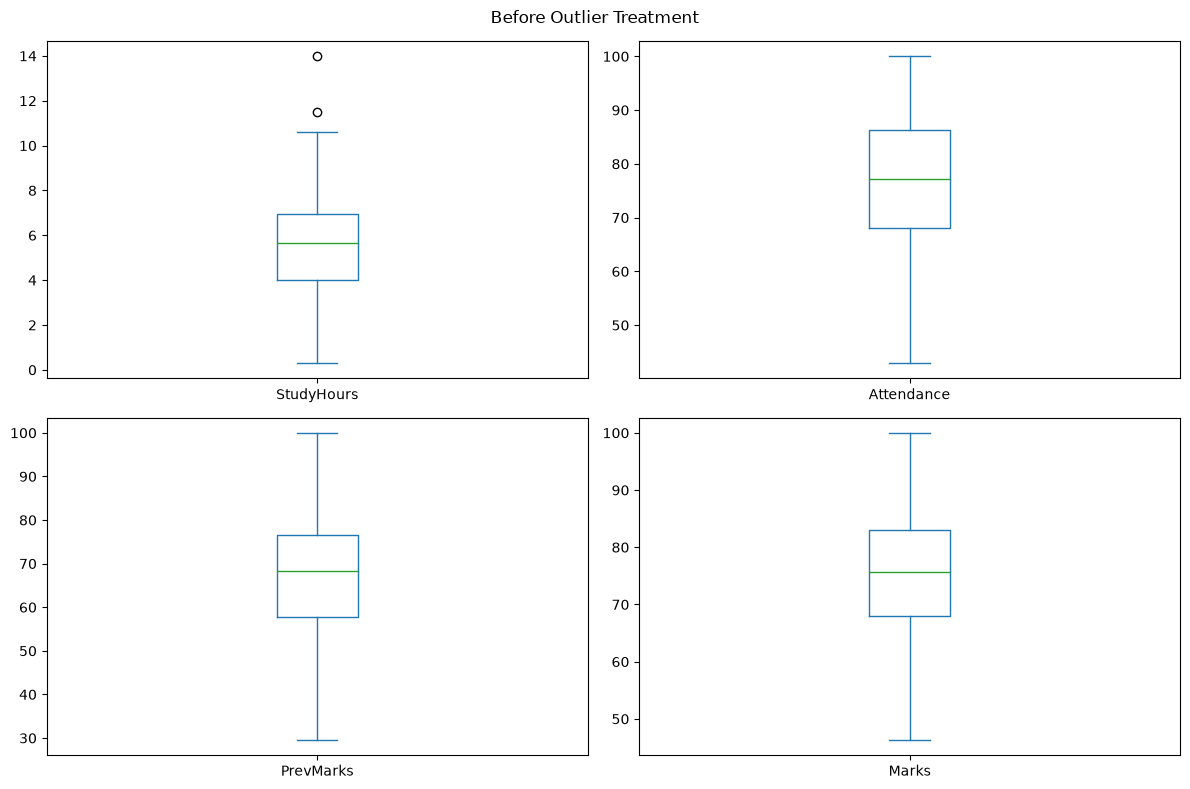

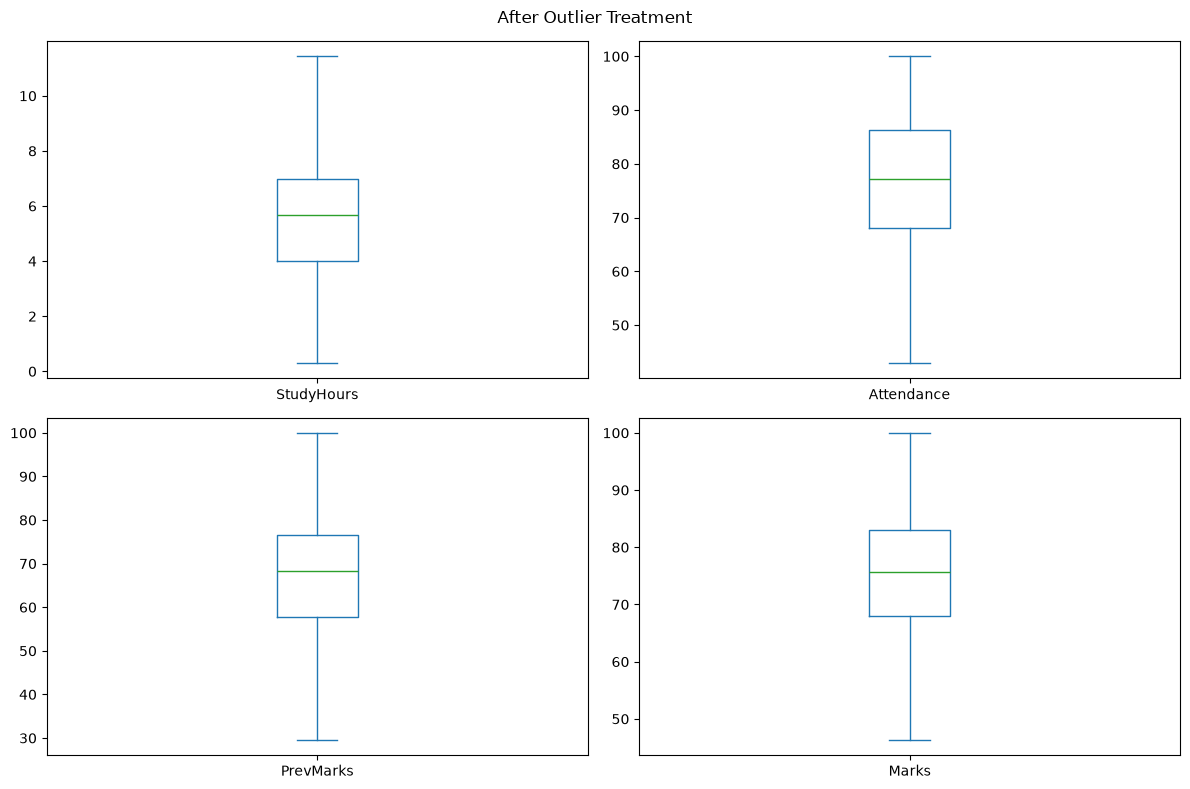


Dataset after Outlier Treatment:
  StudentID  StudyHours  Attendance  PrevMarks  Marks Branch Result
0     S1000        5.08       82.32      65.44  82.46    ISE   Pass
1     S1001        6.16       68.27      82.55  79.14    CSD   Pass
2     S1002        5.42       98.16      67.71  76.89    CSE   Pass
3     S1003        2.93       79.50      68.25  62.16    ISE   Fail
4     S1004        8.01       93.33      60.55  86.49    ISE   Pass

Treated dataset saved successfully!


In [3]:

# Program: Outlier Detection and Treatment using IQR and Z-score

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Load the dataset
df = pd.read_csv("students.csv")

print("Original Dataset:")
print(df.head())

# Select numerical columns
numeric_cols = df.select_dtypes(include=np.number).columns

print("\nNumerical Columns:")
print(list(numeric_cols))


# Step 2: Detect outliers using IQR method
print("\n--- Outlier Detection using IQR ---")

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    print(f"{col}: {count} outliers")


# Step 3: Detect outliers using Z-score method
print("\n--- Outlier Detection using Z-score ---")

for col in numeric_cols:
    mean = df[col].mean()
    std = df[col].std()

    if std == 0:
        print(f"{col}: 0 outliers")
        continue

    z_score = (df[col] - mean) / std
    count = (z_score.abs() > 3).sum()

    print(f"{col}: {count} outliers")


# Step 4: Plot boxplots before treatment
df_before = df.copy()

df_before[numeric_cols].plot(
    kind="box",
    subplots=True,
    layout=(2, 2),
    figsize=(12, 8),
    title="Before Outlier Treatment"
)

plt.tight_layout()
plt.show()


# Step 5: Treat outliers using IQR capping
df_treated = df.copy()

for col in numeric_cols:
    Q1 = df_treated[col].quantile(0.25)
    Q3 = df_treated[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df_treated[col] = df_treated[col].clip(lower, upper)


# Step 6: Plot boxplots after treatment
df_treated[numeric_cols].plot(
    kind="box",
    subplots=True,
    layout=(2, 2),
    figsize=(12, 8),
    title="After Outlier Treatment"
)

plt.tight_layout()
plt.show()


# Step 7: Display and save the treated dataset
print("\nDataset after Outlier Treatment:")
print(df_treated.head())

df_treated.to_csv("students_treated.csv", index=False)

print("\nTreated dataset saved successfully!")
